In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sales_data_sample.csv to sales_data_sample (2).csv


In [ ]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print(df.head())
print(df.shape)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

Duplicate rows: 0


In [ ]:
print(df.isnull().sum())

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64


In [ ]:
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

X = X.dropna()

print(X.head())

   QUANTITYORDERED  PRICEEACH    SALES
0               30      95.70  2871.00
1               34      81.35  2765.90
2               41      94.74  3884.34
3               45      83.26  3746.70
4               49     100.00  5205.27


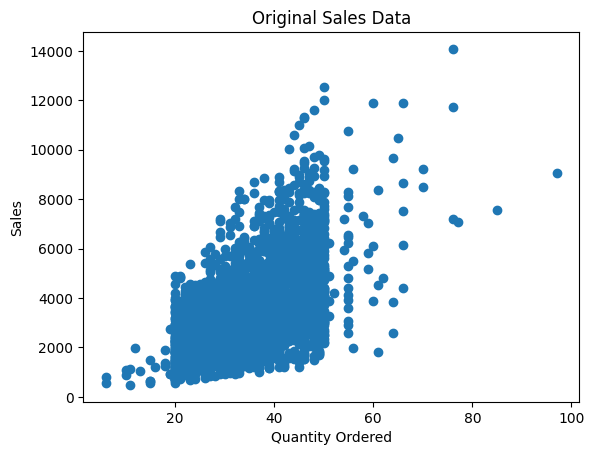

In [ ]:
plt.scatter(X["QUANTITYORDERED"], X["SALES"])

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("Original Sales Data")

plt.show()

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

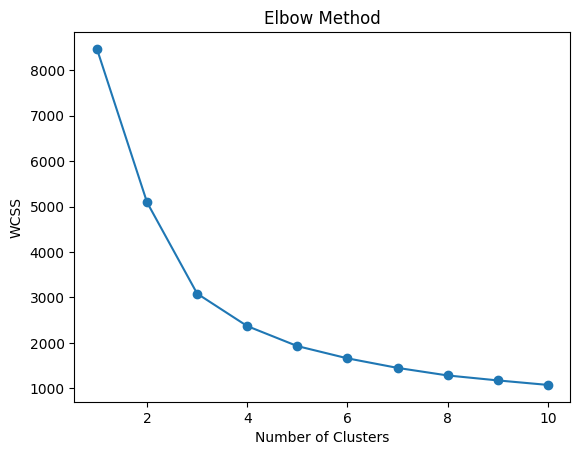

In [ ]:
scores = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    scores.append(kmeans.inertia_)

plt.plot(range(1, 11), scores, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.show()

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

labels = kmeans.fit_predict(X_scaled)

X["Cluster"] = labels

print(X.head())

   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        0
4               49     100.00  5205.27        1


In [ ]:
print("Cluster Centers:")
print(kmeans.cluster_centers_)

Cluster Centers:
[[ 0.90481029 -0.88391854 -0.36756702]
 [ 0.89226775  0.76664835  1.29480794]
 [-0.75172142  0.63583763 -0.18225326]
 [-0.70261296 -1.32187138 -1.06766307]]


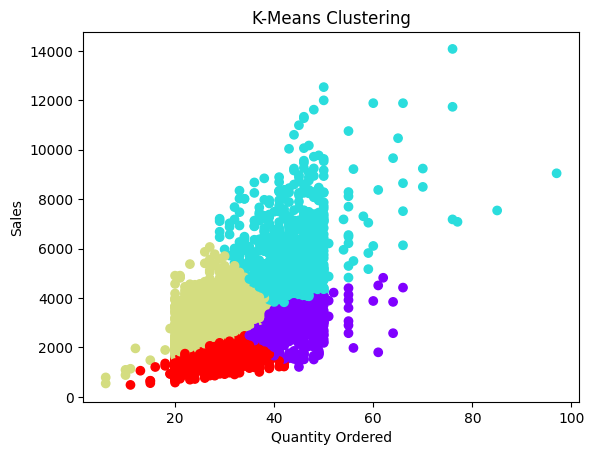

In [ ]:
plt.scatter(X["QUANTITYORDERED"], X["SALES"],
            c=labels, cmap="rainbow")

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering")

plt.show()

In [ ]:
print("Records in each cluster:")
print(X["Cluster"].value_counts())

Records in each cluster:
Cluster
2    989
1    751
3    564
0    519
Name: count, dtype: int64


In [ ]:
print(X.head(10))

print("\nNumber of records in each cluster:")
print(X["Cluster"].value_counts())

   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        0
4               49     100.00  5205.27        1
5               36      96.66  3479.76        2
6               29      86.13  2497.77        2
7               48     100.00  5512.32        1
8               22      98.57  2168.54        2
9               41     100.00  4708.44        1

Number of records in each cluster:
Cluster
2    989
1    751
3    564
0    519
Name: count, dtype: int64
